# AI Agent Adoption & Workplace Productivity (2024–2026)
### Exploratory Data Analysis • Data Quality • Feature Engineering • Business Insights

**Project objective**  
Explore how AI-agent adoption varies across industries, job roles, agent types, and company sizes; assess associations with productivity, time savings, training, job satisfaction, and trust in AI.

**Questions investigated**
1. How is AI-agent usage distributed?
2. Which industries and job roles are most represented?
3. What does the productivity-change distribution look like?
4. Do average weekly hours saved differ by AI-agent type?
5. Are AI skill levels associated with training hours?
6. How are job satisfaction and trust in AI related?
7. What data-quality issues need attention?
8. What additional indicators can be derived responsibly?

> **Interpretation note:** This is an observational dataset. Group differences and correlations describe associations; they do not prove that AI adoption caused productivity or satisfaction changes. The dataset's representativeness and collection methodology should be checked before generalizing beyond the sample.

## 1. Setup and reproducibility

Run this notebook from the folder containing the CSV, or update `DATA_PATH` below. The source file is not modified. Cleaned data and project outputs are saved in an `outputs/` folder.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

DATA_PATH = Path("AI_Agent_Adoption_Workplace_Productivity_2024_2026.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place AI_Agent_Adoption_Workplace_Productivity_2024_2026.csv "
        "in the notebook folder or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]:,} columns.")
display(df.head())

Loaded 523 rows and 22 columns.


,Record_ID,Year,Country,Industry,Company_Size,Job_Role,Age_Group,AI_Agent_Usage,AI_Agent_Type,Tasks_Automated,Hours_Saved_Per_Week,Productivity_Change_Percent,AI_Skill_Level,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Workload_Level,Trust_in_AI,Human_AI_Collaboration,Error_Rate,Job_Risk_Level,Overall_AI_Impact
0,AIW-0001,2025,France,Finance & Banking,Enterprise (1000+),Sales Representative,35-44,High,WORKFLOW AUTOMATION AGENT,43.00,8.40,91.60,Intermediate,15.00,44.39,7.00,Moderate,6.00,High,7.00,Moderate,Positive
1,AIW-0002,2025,Germany,Energy & Utilities,Medium (51-250),Software Engineer,45-54,Very High,Coding Agent,31.00,9.00,8.10,Intermediate,2.00,161.80,8.00,Low,7.00,High,5.40,Very High,Positive
2,AIW-0003,2025,Germany,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,55+,Low,Data Processing Agent,6.00,0.60,-11.20,Beginner,25.00,41.80,10.00,Moderate,6.00,Moderate,6.70,Low,Positive
3,AIW-0004,2025,France,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,35-44,High,Content Generation Agent,16.00,NaN,5.90,Advanced,59.00,42.40,5.00,High,6.00,High,8.20,Moderate,Neutral
4,AIW-0005,2024,India,Finance & Banking,Enterprise (1000+),HR Specialist,25-34,High,Scheduling & Admin Agent,23.00,6.50,-8.40,Intermediate,0.00,27.01,NaN,Moderate,5.00,Moderate,9.60,Moderate,Neutral


## 2. Dataset overview

Inspect the dimensions, column names, data types, sample records, and descriptive statistics before making cleaning decisions.

In [2]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

display(df.describe(include="all").T)

Shape: (523, 22)

Column names:
['Record_ID', 'Year', 'Country', 'Industry', 'Company_Size', 'Job_Role', 'Age_Group', 'AI_Agent_Usage', 'AI_Agent_Type', 'Tasks_Automated', 'Hours_Saved_Per_Week', 'Productivity_Change_Percent', 'AI_Skill_Level', 'Training_Hours', 'Monthly_AI_Cost', 'Job_Satisfaction', 'Workload_Level', 'Trust_in_AI', 'Human_AI_Collaboration', 'Error_Rate', 'Job_Risk_Level', 'Overall_AI_Impact']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 523 entries, 0 to 522
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Record_ID                    523 non-null    object 
 1   Year                         523 non-null    int64  
 2   Country                      523 non-null    object 
 3   Industry                     523 non-null    object 
 4   Company_Size                 523 non-null    object 
 5   Job_Role                     523 non-

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,523,523,AIW-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,523.00,NaN,NaN,NaN,"2,025.19",0.78,"2,024.00","2,025.00","2,025.00","2,026.00","2,026.00"
Country,523,28,United States,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Industry,523,20,Technology,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company_Size,523,12,Medium (51-250),153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Role,523,21,Software Engineer,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age_Group,515,9,25-34,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Agent_Usage,523,11,Moderate,174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Agent_Type,523,15,Multi-Agent System,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tasks_Automated,518.00,NaN,NaN,NaN,33.17,34.64,0.00,11.00,23.00,42.75,391.00


## 3. Data quality audit

### 3.1 Missing values, duplicates, and empty strings

Missingness is measured before imputation. Duplicate rows are reported before any removal. Empty or whitespace-only strings are treated as missing for object columns.

In [3]:
# Normalize whitespace-only strings to missing without changing non-empty values.
object_cols = df.select_dtypes(include=["object", "string"]).columns
for col in object_cols:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

missing_audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing_audit)
print("Exact duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent,dtype
Error_Rate,18,3.44,float64
Training_Hours,15,2.87,float64
Job_Satisfaction,12,2.29,float64
Trust_in_AI,9,1.72,float64
Age_Group,8,1.53,object
Hours_Saved_Per_Week,8,1.53,float64
Monthly_AI_Cost,6,1.15,float64
Productivity_Change_Percent,6,1.15,float64
Tasks_Automated,5,0.96,float64
AI_Skill_Level,3,0.57,object


Exact duplicate rows: 0


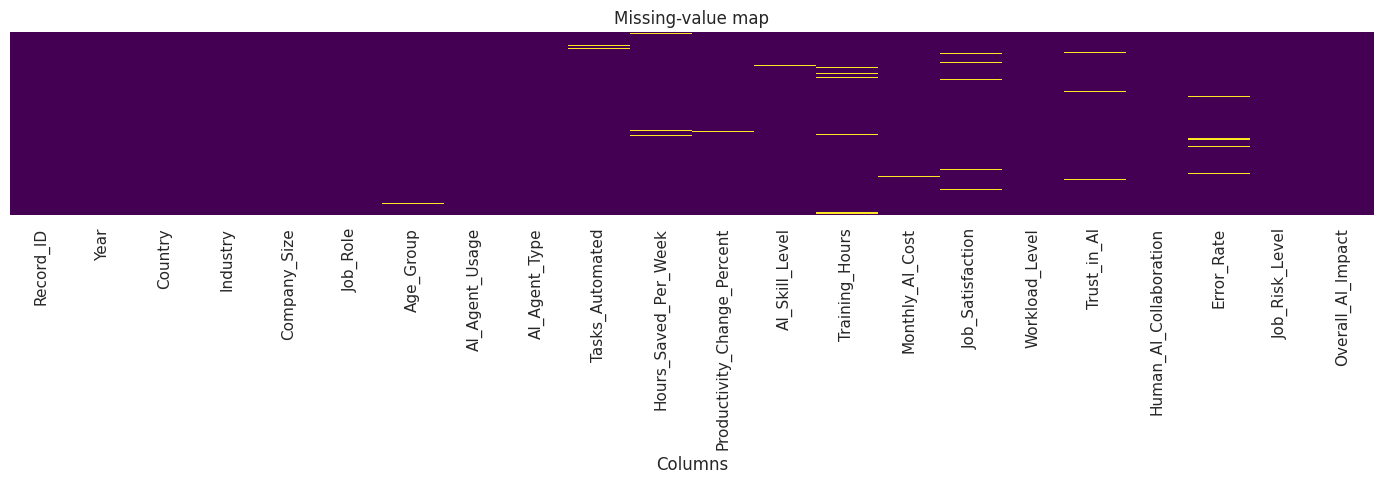

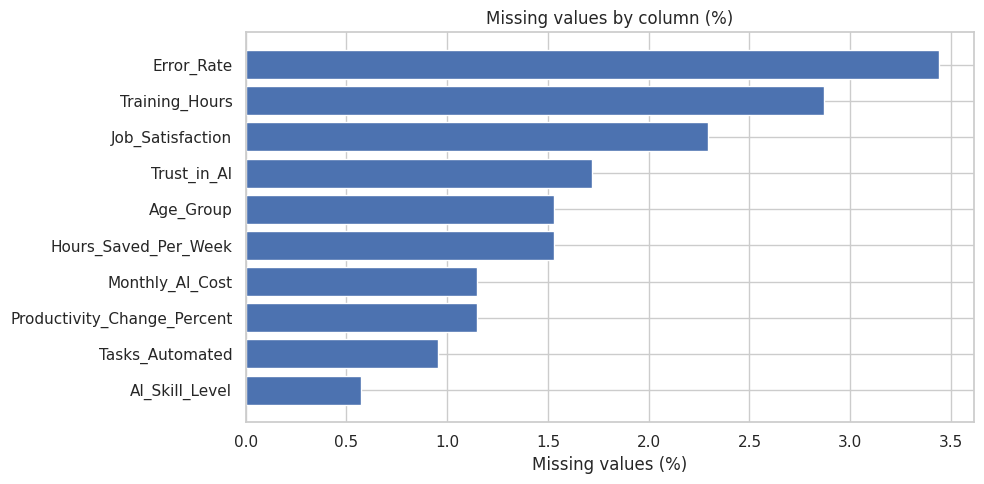

In [4]:
# Visualize missingness only when missing values exist.
if df.isna().any().any():
    plt.figure(figsize=(14, 5))
    sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
    plt.title("Missing-value map")
    plt.xlabel("Columns")
    plt.tight_layout()
    plt.show()

    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    missing_pct = missing_pct[missing_pct > 0]
    plt.figure(figsize=(10, 5))
    missing_plot = missing_pct.rename_axis("column").reset_index(name="missing_percent")
    plt.barh(missing_plot["column"], missing_plot["missing_percent"])
    plt.gca().invert_yaxis()
    plt.title("Missing values by column (%)")
    plt.xlabel("Missing values (%)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

### 3.2 Standardize text categories and validate numeric columns

Text cleanup removes leading/trailing spaces and standardizes capitalization. Known spelling variants in `AI_Skill_Level` are harmonized. Numeric conversion is attempted only for columns that should be numeric; unparseable values become missing and are counted.

In [5]:
# Clean categorical text consistently.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Normalize capitalization in controlled categorical vocabularies before alias mapping.
for col in ["AI_Agent_Usage", "AI_Agent_Type", "AI_Skill_Level",
            "Workload_Level", "Human_AI_Collaboration", "Overall_AI_Impact",
            "Job_Risk_Level", "Company_Size"]:
    if col in df.columns:
        df[col] = df[col].str.title()

# Harmonize only clearly equivalent labels; preserve distinct business categories.
category_maps = {
    "AI_Agent_Usage": {
        "high": "High", "HIGH": "High", "low": "Low", "LOW": "Low",
        "moderate": "Moderate", "VERY HIGH": "Very High", "very high": "Very High"
    },
    "AI_Agent_Type": {
        "coding agent": "Coding Agent",
        "workflow automation agent": "Workflow Automation Agent",
        "customer service agent": "Customer Service Agent",
        "research & analysis agent": "Research & Analysis Agent",
        "scheduling & admin agent": "Scheduling & Admin Agent"
    },
    "AI_Skill_Level": {
        "advanced": "Advanced", "Adv.": "Advanced", "EXPERT": "Expert",
        "expert": "Expert", "intermediate": "Intermediate", "Mid": "Intermediate",
        "Novice": "Beginner"
    },
    "Workload_Level": {
        "HIGH": "High", "high": "High", "LOW": "Low", "low": "Low",
        "MODERATE": "Moderate", "moderate": "Moderate"
    },
    "Human_AI_Collaboration": {
        "HIGH": "High", "high": "High", "LOW": "Low", "low": "Low"
    },
    "Overall_AI_Impact": {
        "positive": "Positive", "Positive ": "Positive",
        "neutral": "Neutral", "Negative ": "Negative",
        "highly positive": "Highly Positive", "Highly Positive ": "Highly Positive"
    },
    "Job_Risk_Level": {"High ": "High"},
    "Company_Size": {
        "Small": "Small (1-50)", "small (1-50)": "Small (1-50)",
        "Medium": "Medium (51-250)", "Mid-size (51-250)": "Medium (51-250)",
        "Large": "Large (251-1000)", "Large Enterprise (1000+)": "Enterprise (1000+)",
        "Enterprise": "Enterprise (1000+)", "enterprise (1000+)": "Enterprise (1000+)"
    },
    "Country": {
        "canada": "Canada", "Canada ": "Canada", "Canada": "Canada",
        "PAKISTAN": "Pakistan", "UK": "United Kingdom", "U.K.": "United Kingdom",
        "united kingdom": "United Kingdom", "United States of America": "United States",
        "united states": "United States",
        "United States Of America": "United States",
        "U.K.": "United Kingdom"
    },
    "AI_Agent_Type": {
        "coding agent": "Coding Agent",
        "workflow automation agent": "Workflow Automation Agent",
        "customer service agent": "Customer Service Agent",
        "research & analysis agent": "Research & Analysis Agent",
        "scheduling & admin agent": "Scheduling & Admin Agent"
    }
}
for col, mapping in category_maps.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping)

# Standardize a few clearly equivalent labels in industry and job-role fields.
if "Industry" in df.columns:
    df["Industry"] = df["Industry"].replace({
        "Banking & Finance": "Finance & Banking",
        "finance & banking": "Finance & Banking",
        "IT / Technology": "Technology",
        "technology": "Technology",
        "manufacturing": "Manufacturing",
        "Telecom": "Telecommunications"
    })
if "Job_Role" in df.columns:
    df["Job_Role"] = df["Job_Role"].replace({
        "Project manager": "Project Manager",
        "Finance Analyst": "Financial Analyst",
        "SWE": "Software Engineer"
    })
if "Age_Group" in df.columns:
    df["Age_Group"] = df["Age_Group"].replace({
        "25–34": "25-34", "35 to 44": "35-44", "45 to 54": "45-54",
        "45–54": "45-54"
    })

# Convert known numeric measures safely when present.
expected_numeric = [
    "Productivity_Change_Percent", "Hours_Saved_Per_Week",
    "Training_Hours", "Job_Satisfaction", "Trust_in_AI",
    "Error_Rate", "Tasks_Automated", "Monthly_AI_Cost"
]
conversion_report = {}
for col in expected_numeric:
    if col in df.columns:
        before_missing = df[col].isna().sum()
        df[col] = pd.to_numeric(df[col], errors="coerce")
        conversion_report[col] = int(df[col].isna().sum() - before_missing)

print("New missing values created during numeric conversion:")
display(pd.Series(conversion_report, name="new_missing_values").to_frame())
display(df.dtypes.astype(str).to_frame("dtype"))


New missing values created during numeric conversion:


,new_missing_values
Productivity_Change_Percent,0
Hours_Saved_Per_Week,0
Training_Hours,0
Job_Satisfaction,0
Trust_in_AI,0
Error_Rate,0
Tasks_Automated,0
Monthly_AI_Cost,0


,dtype
Record_ID,string
Year,int64
Country,string
Industry,string
Company_Size,string
Job_Role,string
Age_Group,string
AI_Agent_Usage,string
AI_Agent_Type,string
Tasks_Automated,float64


In [6]:
# Flag suspicious numeric values for review; do not silently delete them.
range_checks = {
    "Training_Hours": (0, None),
    "Tasks_Automated": (0, None),
    "Hours_Saved_Per_Week": (0, None),
    "Job_Satisfaction": (0, 10),
    "Trust_in_AI": (0, 10),
    "Error_Rate": (0, 100),
    "Monthly_AI_Cost": (0, None)
}
range_issues = []
for col, (lower, upper) in range_checks.items():
    if col not in df.columns:
        continue
    invalid = pd.Series(False, index=df.index)
    if lower is not None:
        invalid |= df[col] < lower
    if upper is not None:
        invalid |= df[col] > upper
    range_issues.append({
        "column": col, "values_outside_assumed_range": int(invalid.sum()),
        "assumed_range": f"{lower} to {upper if upper is not None else 'no upper limit'}"
    })
range_audit = pd.DataFrame(range_issues)
display(range_audit)

# These are flags only. Confirm units and scale definitions with the dataset documentation
# before correcting or excluding any observation.


,column,values_outside_assumed_range,assumed_range
0,Training_Hours,1,0 to no upper limit
1,Tasks_Automated,0,0 to no upper limit
2,Hours_Saved_Per_Week,0,0 to no upper limit
3,Job_Satisfaction,0,0 to 10
4,Trust_in_AI,1,0 to 10
5,Error_Rate,0,0 to 100
6,Monthly_AI_Cost,0,0 to no upper limit


### 3.3 Duplicate handling

Exact duplicate records are removed only after the duplicate count has been recorded. If rows are repeated because they represent legitimate repeated observations, a unique record identifier or documented business key should be used instead of blindly deleting them.

In [7]:
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {duplicates_before:,}")
print(f"Rows remaining: {len(df):,}")

Exact duplicate rows removed: 0
Rows remaining: 523


### 3.4 Missing-value treatment

**Decision rule:** numeric variables use the median (robust to skew and extreme values); categorical variables use the mode. A column that is entirely missing is left unchanged and flagged. Imputation indicators are retained so downstream users can identify which values were filled.

For a predictive model, imputation parameters should be learned from the training set only. Here, the imputation is for descriptive analysis and a reusable cleaned analysis file.

In [8]:
imputation_log = []

for col in df.columns:
    n_missing = int(df[col].isna().sum())
    if n_missing == 0:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        fill_value = df[col].median()
        method = "median"
    else:
        modes = df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else np.nan
        method = "mode"

    if pd.isna(fill_value):
        imputation_log.append({
            "column": col, "missing_before": n_missing,
            "method": "not imputed (no observed values)", "fill_value": np.nan
        })
        continue

    df[f"{col}_was_missing"] = df[col].isna().astype("int8")
    df[col] = df[col].fillna(fill_value)
    imputation_log.append({
        "column": col, "missing_before": n_missing,
        "method": method, "fill_value": fill_value
    })

imputation_log = pd.DataFrame(imputation_log)
display(imputation_log)
print("Remaining missing values:", int(df.isna().sum().sum()))

,column,missing_before,method,fill_value
0,Age_Group,8,mode,25-34
1,Tasks_Automated,5,median,23.00
2,Hours_Saved_Per_Week,8,median,4.30
3,Productivity_Change_Percent,6,median,8.10
4,AI_Skill_Level,3,mode,Intermediate
5,Training_Hours,15,median,13.00
6,Monthly_AI_Cost,6,median,57.72
7,Job_Satisfaction,12,median,7.00
8,Trust_in_AI,9,median,6.00
9,Error_Rate,18,median,8.20


Remaining missing values: 0


## 4. Exploratory data analysis (EDA)

The cells below are conditional: if a column is not present in the supplied file, the relevant analysis is skipped with a clear message rather than failing.

In [9]:
def has_cols(*cols):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        print("Skipped — missing column(s):", ", ".join(missing))
        return False
    return True

def count_bar(column, title, top_n=None, figsize=(10, 5)):
    if not has_cols(column):
        return
    counts = df[column].value_counts(dropna=False)
    if top_n:
        counts = counts.head(top_n)
    plt.figure(figsize=figsize)
    plot_counts = counts.rename_axis("category").reset_index(name="records")
    plot_counts["category"] = plot_counts["category"].astype(str)
    plt.barh(plot_counts["category"], plot_counts["records"])
    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Number of records")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
    display(counts.rename("records").to_frame())

### 4.1 AI-agent usage distribution

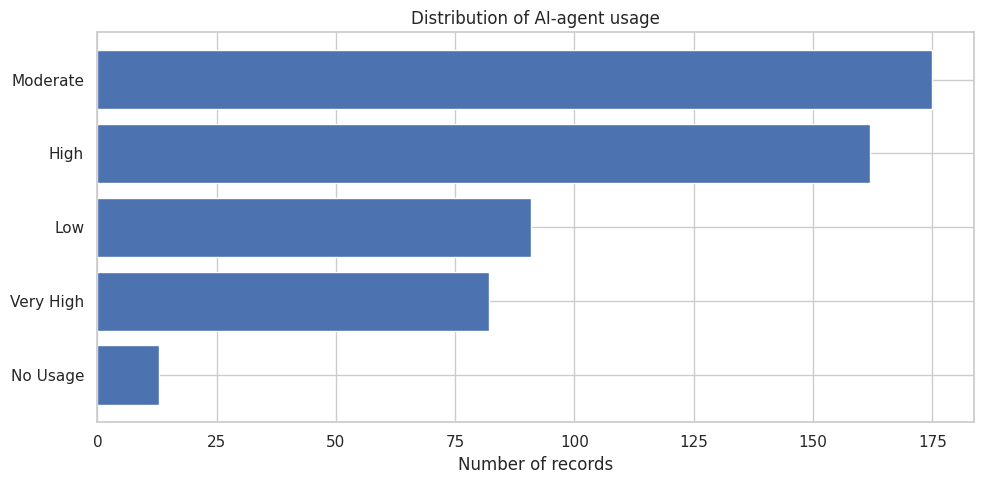

,records
AI_Agent_Usage,
Moderate,175
High,162
Low,91
Very High,82
No Usage,13


In [10]:
count_bar("AI_Agent_Usage", "Distribution of AI-agent usage")

### 4.2 Most represented industries and job roles

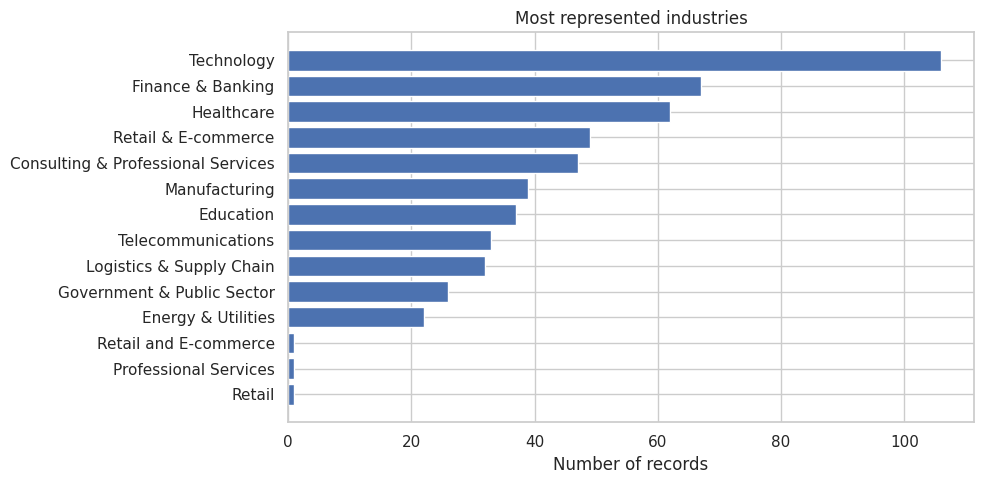

,records
Industry,
Technology,106
Finance & Banking,67
Healthcare,62
Retail & E-commerce,49
Consulting & Professional Services,47
Manufacturing,39
Education,37
Telecommunications,33
Logistics & Supply Chain,32


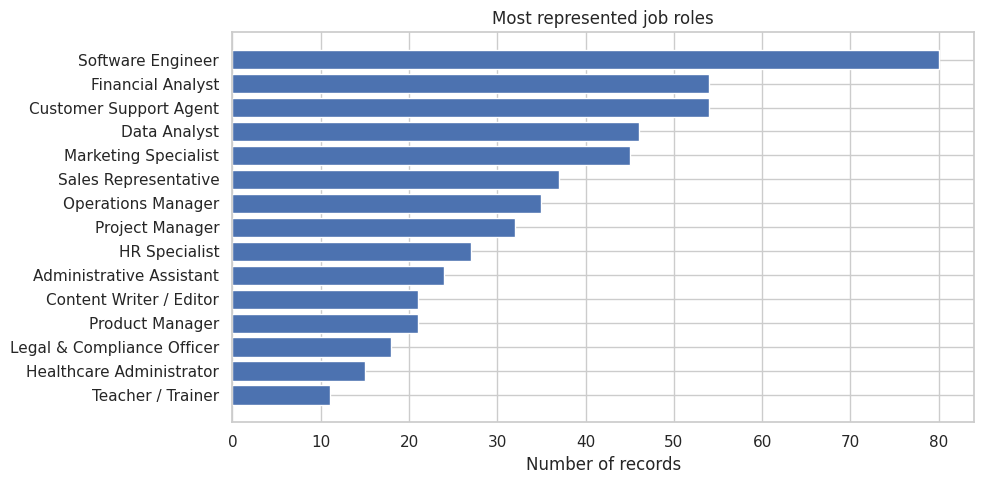

,records
Job_Role,
Software Engineer,80
Financial Analyst,54
Customer Support Agent,54
Data Analyst,46
Marketing Specialist,45
Sales Representative,37
Operations Manager,35
Project Manager,32
HR Specialist,27


In [11]:
count_bar("Industry", "Most represented industries", top_n=15)
count_bar("Job_Role", "Most represented job roles", top_n=15)

### 4.3 Productivity-change distribution

Records: 523
Mean: 10.23 % | Median: 8.1 %
Minimum: -41.5 % | Maximum: 128.3 %


,records
Increase,402
Decrease,121


,percent
Increase,76.86
Decrease,23.14


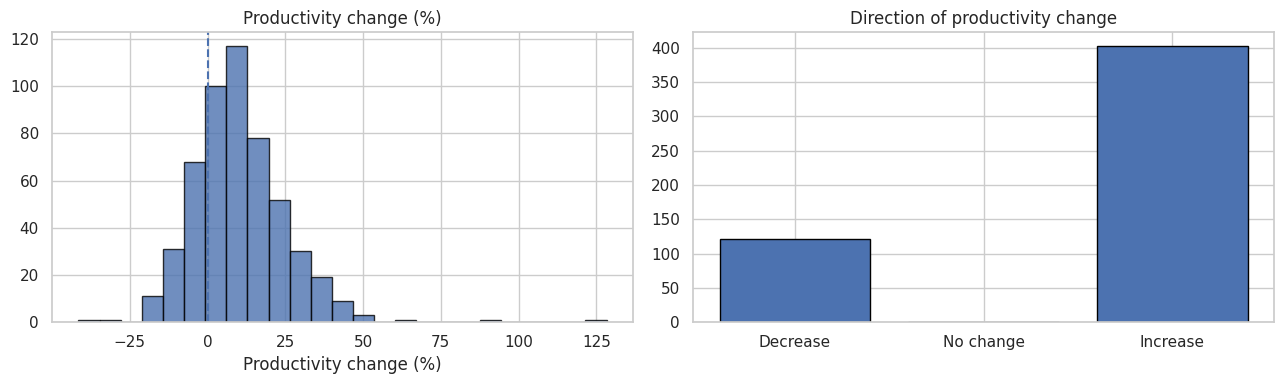

In [12]:
if has_cols("Productivity_Change_Percent"):
    x = df["Productivity_Change_Percent"].dropna()
    print("Records:", len(x))
    print("Mean:", round(x.mean(), 2), "% | Median:", round(x.median(), 2), "%")
    print("Minimum:", round(x.min(), 2), "% | Maximum:", round(x.max(), 2), "%")
    categories = pd.Series(
        np.select([x > 0, x < 0], ["Increase", "Decrease"], default="No change"),
        index=x.index
    )
    display(categories.value_counts().to_frame("records"))
    display((categories.value_counts(normalize=True) * 100).round(2).to_frame("percent"))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(x, bins=25, edgecolor="black", alpha=0.8)
    axes[0].axvline(0, linestyle="--")
    axes[0].set_title("Productivity change (%)")
    axes[0].set_xlabel("Productivity change (%)")
    cat_counts = categories.value_counts().reindex(["Decrease", "No change", "Increase"], fill_value=0)
    axes[1].bar(cat_counts.index, cat_counts.values, edgecolor="black")
    axes[1].set_title("Direction of productivity change")
    axes[1].set_xlabel("")
    plt.tight_layout()
    plt.show()

### 4.4 Hours saved by AI-agent type

,count,mean,median,std
AI_Agent_Type,,,,
Multi-Agent System,97,11.28,8.90,8.20
Data Processing Agent,52,8.04,4.75,8.19
Workflow Automation Agent,60,7.35,4.00,8.18
Coding Agent,61,6.43,4.30,6.03
Research & Analysis Agent,72,5.71,3.95,6.03
Content Generation Agent,84,5.44,3.75,5.41
Scheduling & Admin Agent,40,4.72,3.05,4.15
Customer Service Agent,44,4.02,2.70,4.74
No Agent,13,0.00,0.00,0.00


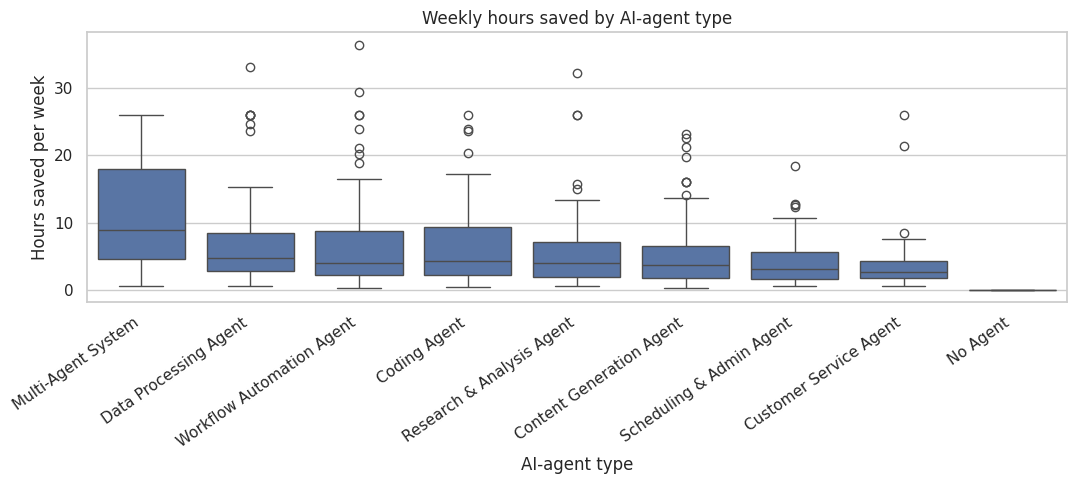

In [13]:
if has_cols("AI_Agent_Type", "Hours_Saved_Per_Week"):
    hours_by_type = (
        df.groupby("AI_Agent_Type")["Hours_Saved_Per_Week"]
          .agg(["count", "mean", "median", "std"])
          .sort_values("mean", ascending=False)
    )
    display(hours_by_type.round(2))
    plt.figure(figsize=(11, 5))
    order = hours_by_type.index.tolist()
    sns.boxplot(data=df, x="AI_Agent_Type", y="Hours_Saved_Per_Week", order=order)
    plt.title("Weekly hours saved by AI-agent type")
    plt.xlabel("AI-agent type")
    plt.ylabel("Hours saved per week")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### 4.5 AI skills and training hours

,count,mean,median,std
AI_Skill_Level,,,,
Expert,53,40.72,38.00,23.80
Advanced,129,24.95,20.00,25.61
Intermediate,210,15.81,11.00,29.30
Beginner,131,8.93,7.00,8.17


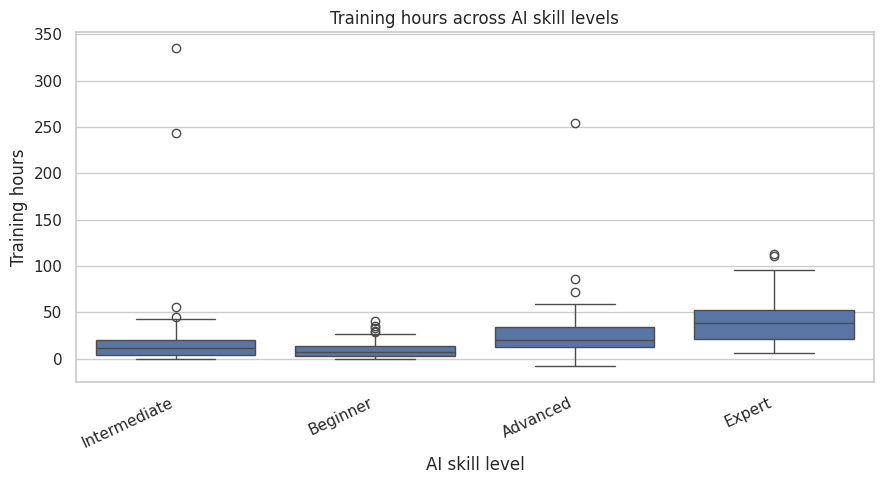

In [14]:
if has_cols("AI_Skill_Level", "Training_Hours"):
    training_by_skill = (
        df.groupby("AI_Skill_Level")["Training_Hours"]
          .agg(["count", "mean", "median", "std"])
          .sort_values("mean", ascending=False)
    )
    display(training_by_skill.round(2))
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x="AI_Skill_Level", y="Training_Hours")
    plt.title("Training hours across AI skill levels")
    plt.xlabel("AI skill level")
    plt.ylabel("Training hours")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### 4.6 Job satisfaction and trust in AI

Pearson correlation: 0.384


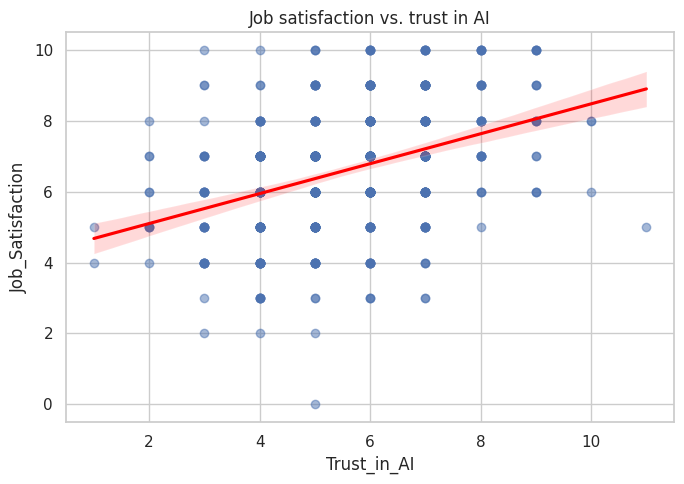

,Job_Satisfaction,Trust_in_AI
AI_Skill_Level,,
Advanced,7.38,6.38
Beginner,5.78,4.27
Expert,8.26,7.13
Intermediate,6.24,5.50


In [15]:
if has_cols("Job_Satisfaction", "Trust_in_AI"):
    print("Pearson correlation:", round(df["Job_Satisfaction"].corr(df["Trust_in_AI"]), 3))
    plt.figure(figsize=(7, 5))
    sns.regplot(data=df, x="Trust_in_AI", y="Job_Satisfaction",
                scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    plt.title("Job satisfaction vs. trust in AI")
    plt.tight_layout()
    plt.show()

    if "AI_Skill_Level" in df.columns:
        display(df.groupby("AI_Skill_Level")[["Job_Satisfaction", "Trust_in_AI"]]
                  .mean().round(2))

### 4.7 Company size and AI usage (if available)

AI_Agent_Usage,High,Low,Moderate,No Usage,Very High
Company_Size,,,,,
Enterprise (1000+),39.70,6.10,30.50,2.30,21.40
Large (251-1000),35.00,13.80,32.50,2.40,16.30
Medium (51-250),20.60,23.20,37.40,1.30,17.40
Mid-Size (51-250),25.00,0.00,50.00,25.00,0.00
Small (1-50),30.90,27.30,31.80,3.60,6.40


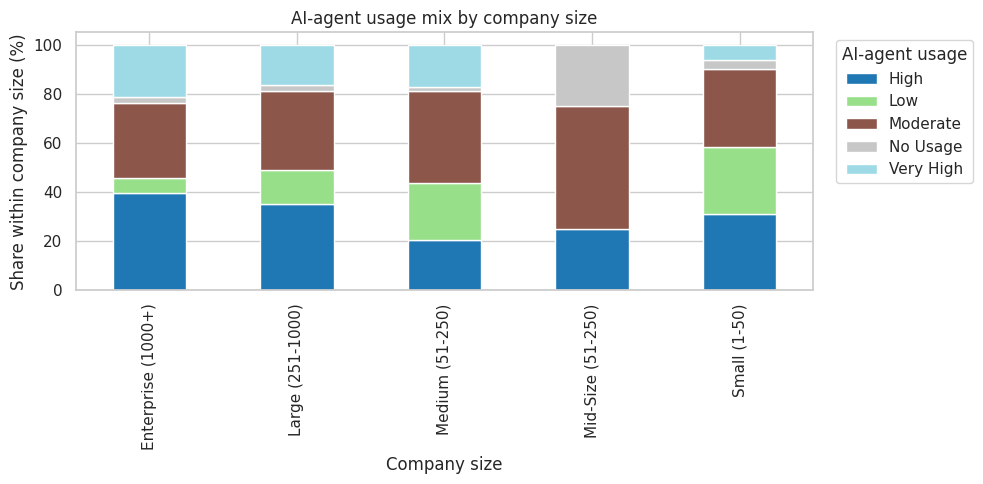

In [16]:
# Select the most likely category field if it exists.
company_size_col = next((c for c in ["Company_Size", "Company_Size_Category", "Organization_Size"]
                         if c in df.columns), None)
usage_col = "AI_Agent_Usage" if "AI_Agent_Usage" in df.columns else None

if company_size_col and usage_col:
    cross = pd.crosstab(df[company_size_col], df[usage_col], normalize="index") * 100
    display(cross.round(1))
    cross.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
    plt.title("AI-agent usage mix by company size")
    plt.xlabel("Company size")
    plt.ylabel("Share within company size (%)")
    plt.legend(title="AI-agent usage", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped — company-size category and/or AI_Agent_Usage column is unavailable.")

### 4.8 Annual distribution (if a year/date field exists)

,records
Year,
2024,120
2025,185
2026,218


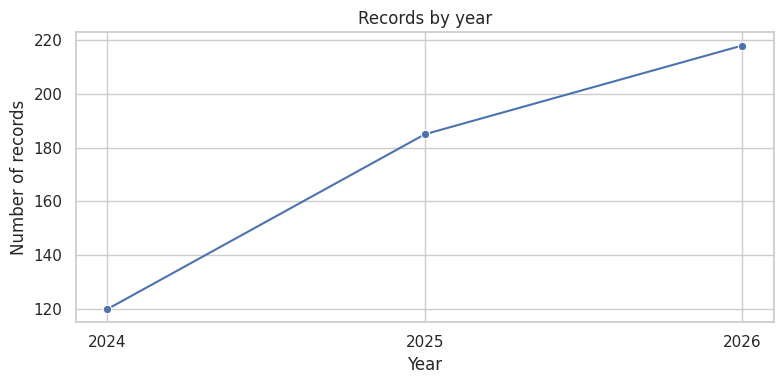

In [17]:
date_col = next((c for c in ["Date", "Survey_Date", "Response_Date", "Created_At"]
                 if c in df.columns), None)
year_col = next((c for c in ["Year", "Survey_Year"] if c in df.columns), None)

if date_col:
    parsed_dates = pd.to_datetime(df[date_col], errors="coerce")
    annual_counts = parsed_dates.dt.year.value_counts().sort_index()
elif year_col:
    annual_counts = pd.to_numeric(df[year_col], errors="coerce").value_counts().sort_index()
else:
    annual_counts = None

if annual_counts is not None:
    display(annual_counts.rename("records").to_frame())
    plt.figure(figsize=(8, 4))
    sns.lineplot(x=annual_counts.index.astype(str), y=annual_counts.values, marker="o")
    plt.title("Records by year")
    plt.xlabel("Year")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped — no recognized date/year column found. Do not infer a year from row order.")

## 5. Numerical relationships

Correlation measures linear association, not causation. A heatmap is generated only for available numeric variables.

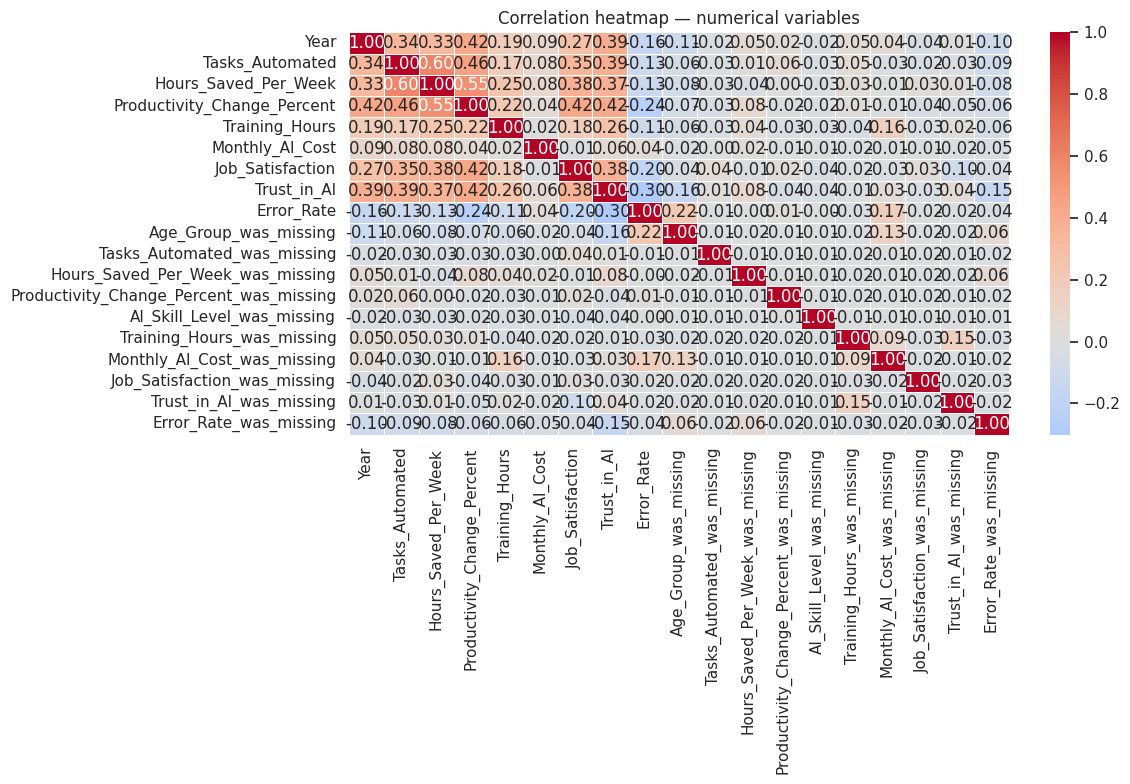

,Year,Tasks_Automated,Hours_Saved_Per_Week,Productivity_Change_Percent,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Trust_in_AI,Error_Rate,Age_Group_was_missing,Tasks_Automated_was_missing,Hours_Saved_Per_Week_was_missing,Productivity_Change_Percent_was_missing,AI_Skill_Level_was_missing,Training_Hours_was_missing,Monthly_AI_Cost_was_missing,Job_Satisfaction_was_missing,Trust_in_AI_was_missing,Error_Rate_was_missing
Year,1.00,0.34,0.33,0.42,0.19,0.09,0.27,0.39,-0.16,-0.11,-0.02,0.05,0.02,-0.02,0.05,0.04,-0.04,0.01,-0.10
Tasks_Automated,0.34,1.00,0.60,0.46,0.17,0.09,0.35,0.39,-0.13,-0.06,-0.03,0.01,0.06,-0.03,0.05,-0.03,-0.02,-0.03,-0.09
Hours_Saved_Per_Week,0.33,0.60,1.00,0.55,0.25,0.09,0.38,0.37,-0.13,-0.08,-0.03,-0.04,0.00,-0.03,0.03,-0.01,0.03,0.01,-0.08
Productivity_Change_Percent,0.42,0.46,0.55,1.00,0.22,0.04,0.42,0.42,-0.24,-0.07,-0.03,0.08,-0.01,-0.02,0.01,-0.01,-0.04,-0.04,-0.07
Training_Hours,0.19,0.17,0.25,0.22,1.00,0.02,0.18,0.26,-0.11,-0.06,-0.03,0.04,-0.03,-0.03,-0.04,0.16,-0.03,0.02,-0.06
Monthly_AI_Cost,0.09,0.09,0.09,0.04,0.02,1.00,-0.01,0.06,0.04,-0.03,-0.01,0.02,-0.01,-0.01,-0.02,-0.01,-0.01,-0.02,-0.05
Job_Satisfaction,0.27,0.35,0.38,0.42,0.18,-0.01,1.00,0.38,-0.20,-0.04,0.04,-0.01,0.02,-0.04,-0.02,-0.03,0.03,-0.10,-0.04
Trust_in_AI,0.39,0.39,0.37,0.42,0.26,0.06,0.38,1.00,-0.30,-0.16,0.01,0.08,-0.04,-0.04,-0.01,0.03,-0.03,0.04,-0.15
Error_Rate,-0.16,-0.13,-0.13,-0.24,-0.11,0.04,-0.20,-0.30,1.00,0.22,-0.01,-0.00,0.01,-0.01,-0.03,0.17,-0.01,-0.02,-0.04
Age_Group_was_missing,-0.11,-0.06,-0.08,-0.07,-0.06,-0.03,-0.04,-0.16,0.22,1.00,-0.01,-0.02,-0.01,-0.01,-0.02,0.13,-0.02,-0.02,0.06


In [18]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr()
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                linewidths=0.5, square=False)
    plt.title("Correlation heatmap — numerical variables")
    plt.tight_layout()
    plt.show()
    display(corr.round(3))
else:
    print("Not enough numeric columns for a correlation heatmap.")

### Training hours vs productivity change

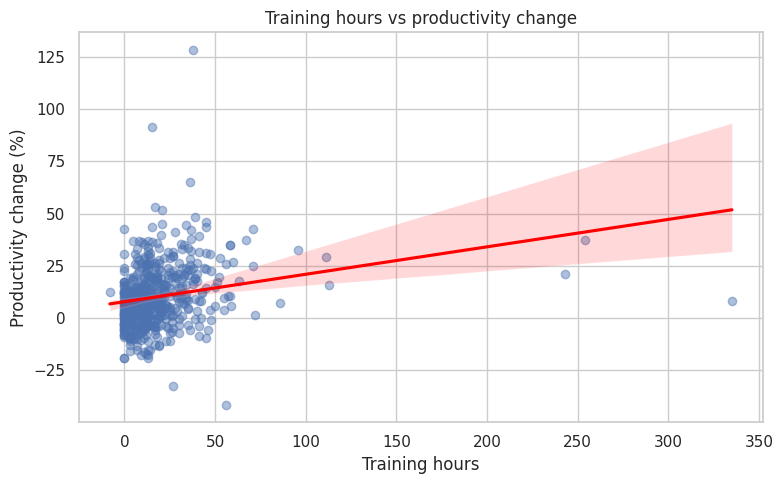

Pearson correlation: 0.222


In [19]:
if has_cols("Training_Hours", "Productivity_Change_Percent"):
    plt.figure(figsize=(8, 5))
    sns.regplot(data=df, x="Training_Hours", y="Productivity_Change_Percent",
                scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
    plt.title("Training hours vs productivity change")
    plt.xlabel("Training hours")
    plt.ylabel("Productivity change (%)")
    plt.tight_layout()
    plt.show()
    print("Pearson correlation:",
          round(df["Training_Hours"].corr(df["Productivity_Change_Percent"]), 3))

## 6. Outlier investigation

Outliers are flagged using the 1.5 × IQR rule. They are **not automatically removed or capped**: an extreme value may be a valid high-performing or high-cost observation. Review source context before changing it.

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,Hours_Saved_Per_Week,2.10,8.90,6.80,-8.10,19.10,48,9.18
1,Training_Hours,6.00,25.00,19.00,-22.50,53.50,22,4.21
2,Productivity_Change_Percent,0.85,18.70,17.85,-25.92,45.48,9,1.72
3,Error_Rate,6.50,10.80,4.30,0.05,17.25,18,3.44
4,Monthly_AI_Cost,28.40,110.36,81.96,-94.53,233.29,25,4.78


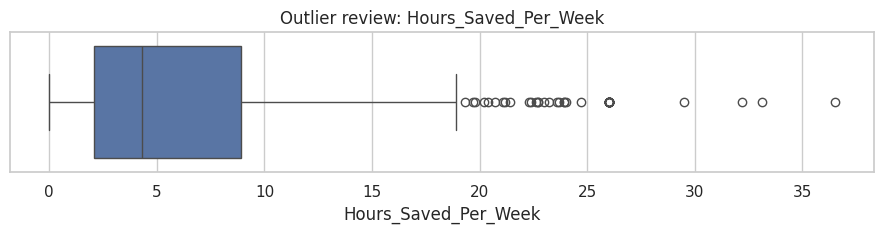

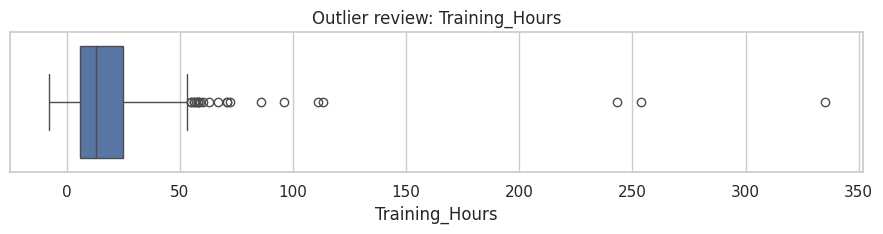

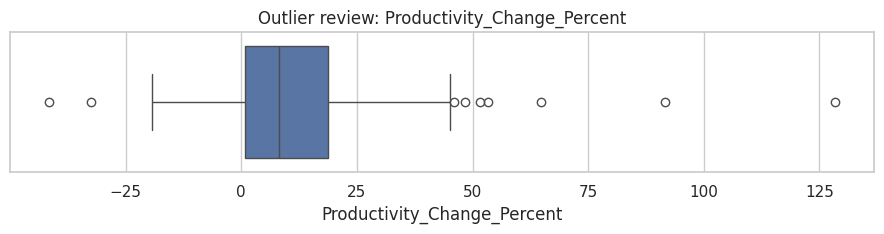

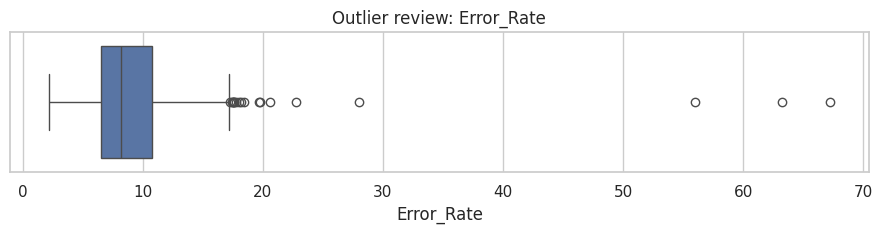

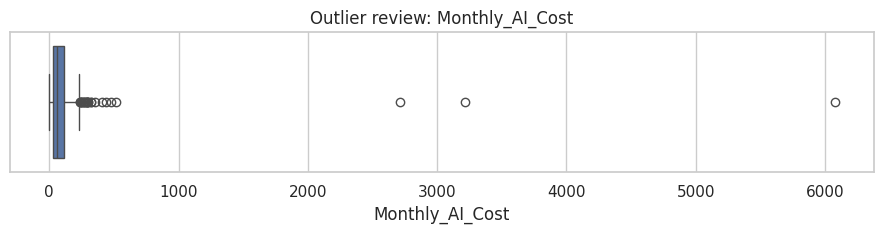

In [20]:
outlier_cols = [
    c for c in ["Hours_Saved_Per_Week", "Training_Hours",
                "Productivity_Change_Percent", "Error_Rate", "Monthly_AI_Cost"]
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]

outlier_rows = []
for col in outlier_cols:
    s = df[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    outlier_rows.append({
        "column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

for col in outlier_cols:
    plt.figure(figsize=(9, 2.5))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier review: {col}")
    plt.tight_layout()
    plt.show()

## 7. Feature engineering

Only features with interpretable definitions are created. Optional features are generated only when their source columns exist.

- **Productivity category:** increase / no change / decrease based on the sign of the measured percentage.
- **Training category:** low / medium / high based on sample tertiles. These are relative to this dataset, not universal skill standards.
- **Automation intensity:** tasks automated divided by an explicit workload denominator, only if a suitable total-task/workload column exists.
- **Cost per hour saved:** monthly AI cost divided by monthly-equivalent hours saved (weekly hours × 4.345). This is an approximate ratio, not a causal ROI calculation.
- **AI adoption score:** no arbitrary composite score is imposed because the dataset's meaning/scale for adoption fields must first be documented.

In [21]:
if "Productivity_Change_Percent" in df.columns:
    df["Productivity_Category"] = np.select(
        [df["Productivity_Change_Percent"] > 0,
         df["Productivity_Change_Percent"] < 0],
        ["Increase", "Decrease"],
        default="No change"
    )

if "Training_Hours" in df.columns and df["Training_Hours"].notna().sum() >= 3:
    # Rank-based tertiles handle repeated values more safely than fixed arbitrary cutoffs.
    ranks = df["Training_Hours"].rank(method="average", pct=True)
    df["Training_Category"] = pd.cut(
        ranks, bins=[0, 1/3, 2/3, 1],
        labels=["Low", "Medium", "High"], include_lowest=True
    )

# Automation intensity: require a documented total-workload denominator.
workload_col = next((c for c in ["Total_Tasks", "Total_Tasks_Per_Week",
                                 "Total_Workload_Tasks"]
                     if c in df.columns), None)
if "Tasks_Automated" in df.columns and workload_col:
    valid = df[workload_col].gt(0)
    df["Automation_Intensity"] = np.where(
        valid, df["Tasks_Automated"] / df[workload_col], np.nan
    )
    print(f"Automation_Intensity = Tasks_Automated / {workload_col}")
else:
    print("Automation_Intensity not created: a documented total-workload denominator is required.")

if "Monthly_AI_Cost" in df.columns and "Hours_Saved_Per_Week" in df.columns:
    monthly_hours_saved = df["Hours_Saved_Per_Week"] * 4.345
    valid = monthly_hours_saved.gt(0)
    df["Cost_Per_Hour_Saved"] = np.where(
        valid, df["Monthly_AI_Cost"] / monthly_hours_saved, np.nan
    )
    print("Cost_Per_Hour_Saved = Monthly_AI_Cost / (Hours_Saved_Per_Week × 4.345)")
else:
    print("Cost_Per_Hour_Saved not created: cost and weekly hours-saved columns are both required.")

display(df.head())

Automation_Intensity not created: a documented total-workload denominator is required.
Cost_Per_Hour_Saved = Monthly_AI_Cost / (Hours_Saved_Per_Week × 4.345)


,Record_ID,Year,Country,Industry,Company_Size,Job_Role,Age_Group,AI_Agent_Usage,AI_Agent_Type,Tasks_Automated,Hours_Saved_Per_Week,Productivity_Change_Percent,AI_Skill_Level,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Workload_Level,Trust_in_AI,Human_AI_Collaboration,Error_Rate,Job_Risk_Level,Overall_AI_Impact,Age_Group_was_missing,Tasks_Automated_was_missing,Hours_Saved_Per_Week_was_missing,Productivity_Change_Percent_was_missing,AI_Skill_Level_was_missing,Training_Hours_was_missing,Monthly_AI_Cost_was_missing,Job_Satisfaction_was_missing,Trust_in_AI_was_missing,Error_Rate_was_missing,Productivity_Category,Training_Category,Cost_Per_Hour_Saved
0,AIW-0001,2025,France,Finance & Banking,Enterprise (1000+),Sales Representative,35-44,High,Workflow Automation Agent,43.00,8.40,91.60,Intermediate,15.00,44.39,7.00,Moderate,6.00,High,7.00,Moderate,Positive,0,0,0,0,0,0,0,0,0,0,Increase,Medium,1.22
1,AIW-0002,2025,Germany,Energy & Utilities,Medium (51-250),Software Engineer,45-54,Very High,Coding Agent,31.00,9.00,8.10,Intermediate,2.00,161.80,8.00,Low,7.00,High,5.40,Very High,Positive,0,0,0,0,0,0,0,0,0,0,Increase,Low,4.14
2,AIW-0003,2025,Germany,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,55+,Low,Data Processing Agent,6.00,0.60,-11.20,Beginner,25.00,41.80,10.00,Moderate,6.00,Moderate,6.70,Low,Positive,0,0,0,0,0,0,0,0,0,0,Decrease,High,16.03
3,AIW-0004,2025,France,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,35-44,High,Content Generation Agent,16.00,4.30,5.90,Advanced,59.00,42.40,5.00,High,6.00,High,8.20,Moderate,Neutral,0,0,1,0,0,0,0,0,0,0,Increase,High,2.27
4,AIW-0005,2024,India,Finance & Banking,Enterprise (1000+),HR Specialist,25-34,High,Scheduling & Admin Agent,23.00,6.50,-8.40,Intermediate,0.00,27.01,7.00,Moderate,5.00,Moderate,9.60,Moderate,Neutral,0,0,0,0,0,0,0,1,0,0,Decrease,Low,0.96


## 8. Additional business views

Productivity_Category,Decrease,Increase
Industry,,
Consulting & Professional Services,19.10,80.90
Education,35.10,64.90
Energy & Utilities,27.30,72.70
Finance & Banking,16.40,83.60
Government & Public Sector,38.50,61.50
Healthcare,22.60,77.40
Logistics & Supply Chain,28.10,71.90
Manufacturing,28.20,71.80
Professional Services,0.00,100.00


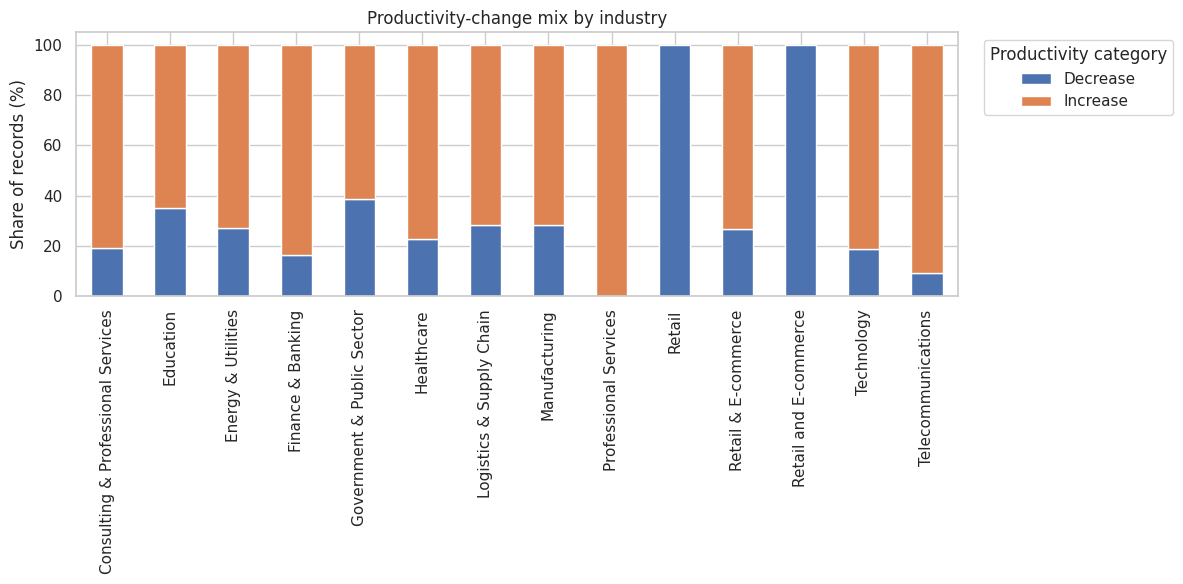

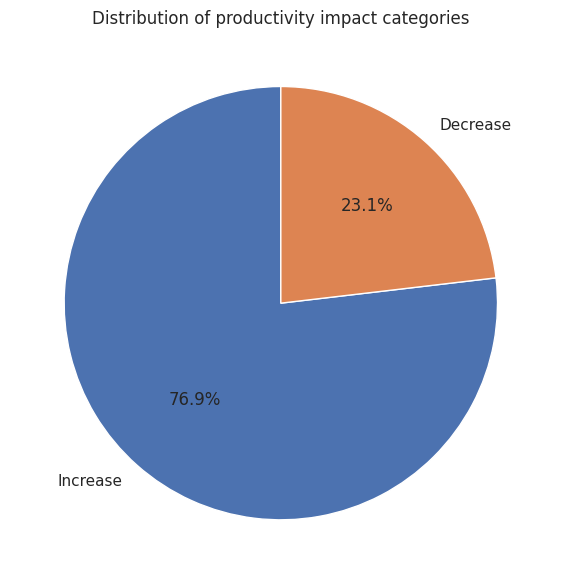

In [22]:
# Productivity categories by industry, if both fields exist.
if has_cols("Industry", "Productivity_Category"):
    industry_productivity = pd.crosstab(
        df["Industry"], df["Productivity_Category"], normalize="index"
    ) * 100
    display(industry_productivity.round(1))
    industry_productivity.plot(kind="bar", stacked=True, figsize=(12, 6))
    plt.title("Productivity-change mix by industry")
    plt.ylabel("Share of records (%)")
    plt.xlabel("")
    plt.legend(title="Productivity category", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

# Pie chart: impact categories, defined from productivity-change direction.
if "Productivity_Category" in df.columns:
    impact_counts = df["Productivity_Category"].value_counts()
    plt.figure(figsize=(6, 6))
    plt.pie(impact_counts, labels=impact_counts.index, autopct="%1.1f%%",
            startangle=90, wedgeprops={"edgecolor": "white"})
    plt.title("Distribution of productivity impact categories")
    plt.tight_layout()
    plt.show()

## 9. Automated findings for the project summary

This section prints dataset-specific facts after the notebook has been run with the source CSV. Review the results and add business context before publishing; do not claim causation.

In [23]:
print("PROJECT SNAPSHOT")
print("-" * 60)
print(f"Records analyzed: {len(df):,}")
print(f"Fields available: {df.shape[1]:,}")
print(f"Missing cells after treatment: {int(df.isna().sum().sum()):,}")

if "AI_Agent_Usage" in df.columns:
    print("\nMost common AI-agent usage value:")
    print(df["AI_Agent_Usage"].value_counts().head(1).to_string())

if "Industry" in df.columns:
    print("\nMost represented industry:")
    print(df["Industry"].value_counts().head(1).to_string())

if "Job_Role" in df.columns:
    print("\nMost represented job role:")
    print(df["Job_Role"].value_counts().head(1).to_string())

if "Productivity_Change_Percent" in df.columns:
    print("\nAverage productivity change (%):",
          round(df["Productivity_Change_Percent"].mean(), 2))

if has_cols("AI_Agent_Type", "Hours_Saved_Per_Week"):
    print("\nAgent type with highest average weekly hours saved:")
    print(df.groupby("AI_Agent_Type")["Hours_Saved_Per_Week"].mean()
            .sort_values(ascending=False).head(1).to_string())

if has_cols("Training_Hours", "Productivity_Change_Percent"):
    print("\nTraining hours / productivity correlation:",
          round(df["Training_Hours"].corr(df["Productivity_Change_Percent"]), 3))

if has_cols("Job_Satisfaction", "Trust_in_AI"):
    print("Job satisfaction / trust correlation:",
          round(df["Job_Satisfaction"].corr(df["Trust_in_AI"]), 3))

PROJECT SNAPSHOT
------------------------------------------------------------
Records analyzed: 523
Fields available: 35
Missing cells after treatment: 13

Most common AI-agent usage value:
AI_Agent_Usage
Moderate    175

Most represented industry:
Industry
Technology    106

Most represented job role:
Job_Role
Software Engineer    80

Average productivity change (%): 10.23

Agent type with highest average weekly hours saved:
AI_Agent_Type
Multi-Agent System   11.28

Training hours / productivity correlation: 0.222
Job satisfaction / trust correlation: 0.384


## 10. Export project outputs

Exports:
- `outputs/ai_agent_adoption_cleaned.csv` — cleaned dataset plus valid engineered features and missingness flags.
- `outputs/data_quality_report.csv` — missingness audit from before imputation.
- `outputs/imputation_log.csv` — the columns imputed and the method used.
- `outputs/outlier_summary.csv` — IQR-based outlier flags summary.
- `outputs/numeric_correlation_matrix.csv` — numerical correlation matrix.

Keep the original source file unchanged. Include the source, data dictionary, and methodology in a public portfolio repository when licensing permits.

In [24]:
df.to_csv(OUTPUT_DIR / "ai_agent_adoption_cleaned.csv", index=False)
missing_audit.to_csv(OUTPUT_DIR / "data_quality_report.csv")
imputation_log.to_csv(OUTPUT_DIR / "imputation_log.csv", index=False)
outlier_summary.to_csv(OUTPUT_DIR / "outlier_summary.csv", index=False)

if numeric_df.shape[1] >= 2:
    numeric_df.corr().to_csv(OUTPUT_DIR / "numeric_correlation_matrix.csv")

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])
range_audit.to_csv(OUTPUT_DIR / "numeric_range_audit.csv", index=False)

Saved outputs to: /mnt/data/outputs
Files: ['numeric_range_audit.csv', 'outlier_summary.csv', 'imputation_log.csv', 'numeric_correlation_matrix.csv', 'ai_agent_adoption_cleaned.csv', 'data_quality_report.csv']


## 11. Key findings from this dataset

The following figures were calculated from the supplied 523-row dataset after categorical-label standardization and the documented median/mode imputation. Treat them as descriptive results for this dataset, not population estimates.

- **Coverage:** 523 records across 2024–2026; the annual record counts are 120, 185, and 218 respectively. This is the distribution of records in the file, not evidence of market-wide growth.
- **Adoption:** Moderate usage is the largest usage group (175 records; 33.5%), followed by High usage (162; 31.0%). 13 records (2.5%) report No Usage.
- **Industry mix:** Technology is most represented (106 records), followed by Finance & Banking (67) and Healthcare (62).
- **Job-role mix:** Software Engineer is the most represented role (80 records); Financial Analyst and Customer Support Agent have 54 each.
- **Productivity:** Among the 517 originally observed productivity values, 396 are positive and 121 negative. The observed mean is approximately 10.26% and median 8.1%. Six missing values are imputed for downstream charts and analysis.
- **Hours saved:** Multi-Agent Systems have the highest mean weekly hours saved among the agent categories with meaningful sample counts (97 records; mean 11.28 hours). The average should be interpreted alongside its distribution and possible confounding factors.
- **Training:** Average training hours differ by skill group: Beginner 8.93, Intermediate 15.81, Advanced 24.95, Expert 40.72. This is consistent with higher training exposure among higher self-reported skill levels, but does not establish that training caused skill gains.
- **Relationships:** Training hours and productivity change show a weak positive Pearson correlation (about 0.22). Productivity change and weekly hours saved show a stronger positive correlation (about 0.55). Job satisfaction and trust in AI are positively correlated (about 0.38). These are associations, not causal effects.
- **Data quality:** 90 missing cells were present across 10 columns; there were no exact duplicate rows. The notebook logs imputation and flags numeric values outside assumed ranges for review.

**Important cleaning decisions:** spelling/capitalization variants were harmonized only where they appeared to represent the same label. The source has no documented denominator for total workload, so Automation Intensity is not fabricated. Cost per hour saved is undefined for records reporting zero weekly hours saved; those 13 values remain missing in that derived metric only.


## 12. Conclusion and limitations

Use the actual outputs above to write 3–5 concise findings. A strong portfolio conclusion should answer:
1. What adoption pattern is most visible in this sample?
2. Which agent types or groups show different average time savings?
3. What is the observed relationship between training, productivity, trust, and satisfaction?
4. Which data-quality limitations could affect the interpretation?
5. What practical next step would you recommend to an organization?

**Limitations to disclose**
- Sample size and sampling method may limit generalizability.
- Self-reported productivity, trust, satisfaction, and time savings may contain recall or response bias.
- Correlation does not establish causation.
- Relative tertile-based training categories are sample-dependent.
- Cost-per-hour-saved is an approximate descriptive ratio and excludes implementation, maintenance, and other indirect costs.
- Missing-value imputation can reduce variability; retain the imputation log and missingness flags.